In [1]:
import numpy as np
import emcee
import corner
import matplotlib.pyplot as plt

In [4]:
from pathlib import Path
backend_path = Path('/home/hedi/HSCNG/peaks/mcmc_peak_results_37.h5')
backend = emcee.backends.HDFBackend(str(backend_path), read_only=True)

In [5]:
chain = backend.get_chain(flat=True, discard=200)

In [50]:
backend.get_autocorr_time()

array([42.10019814, 37.77070071])

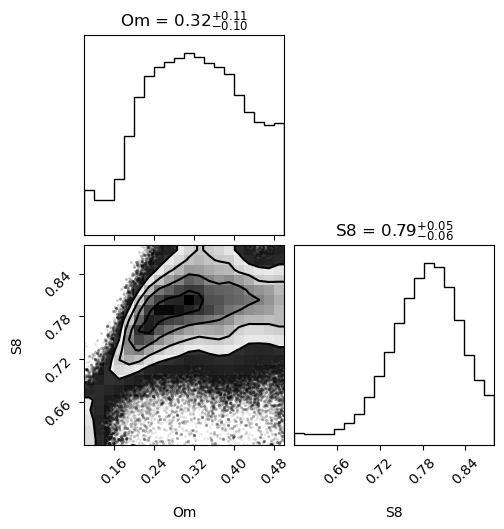

In [4]:
fig = corner.corner(chain, labels=["Om", "S8"], show_titles=True)
fig.show()

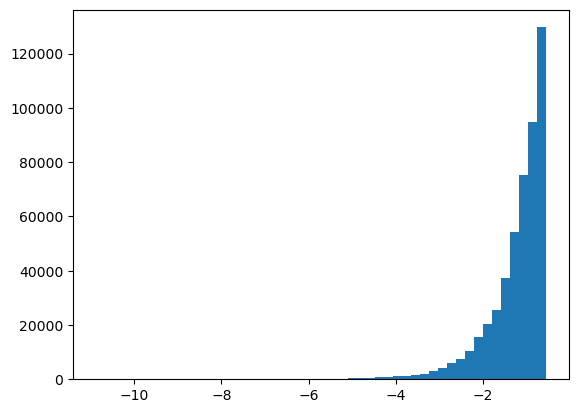

In [5]:
plt.hist(backend.get_log_prob(discard=100, flat=True), bins=50)
plt.show()

In [6]:
import sys
sys.path.append('/home/hedi/HSCNG/peaks')

In [7]:
import importlib
import MCMC_peak_test
importlib.reload(MCMC_peak_test)

<module 'MCMC_peak_test' from '/home/hedi/HSCNG/peaks/MCMC_peak_test.py'>

In [8]:
from MCMC_peak_test import *

In [9]:
mid_val = np.percentile(chain, 50, axis=0)

In [10]:
ln_likelihood(mid_val, True) * (-2)

np.float64(1.2784918163493173)

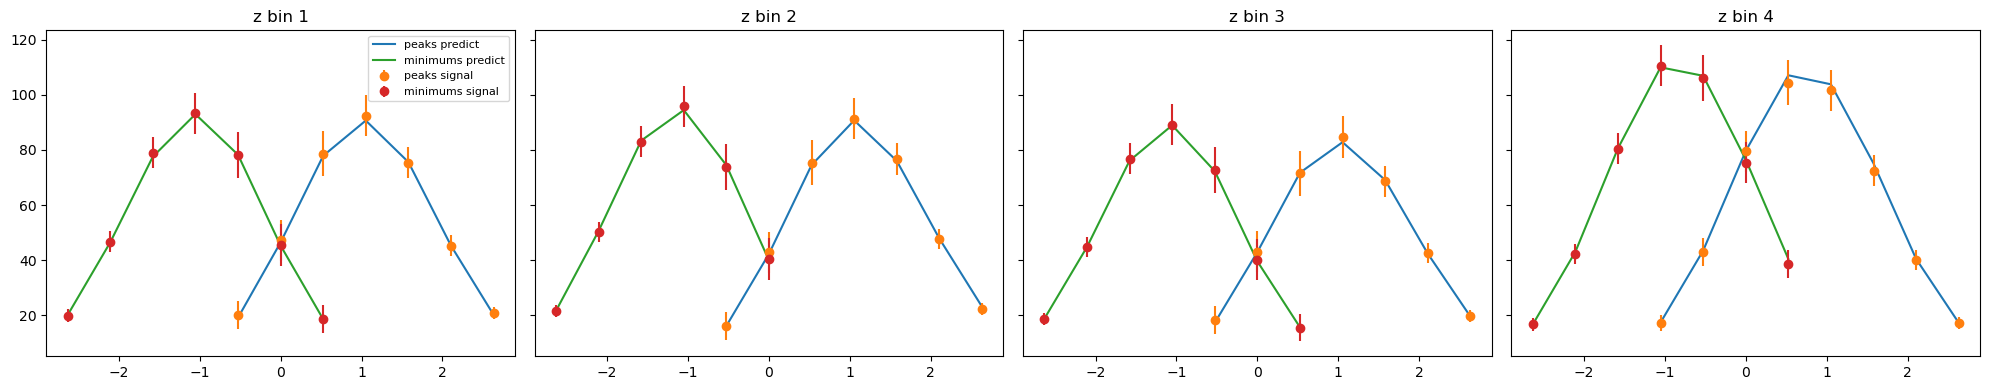

In [12]:
Om, S8 = mid_val
H0 = 0.7

fig, axes = plt.subplots(1, 4, figsize=(20, 4), sharey=True)

for i, ax in enumerate(axes):
    pred_peaks = gpr_peaks[i].predict(np.array([[Om, S8, H0]])).flatten()
    pred_mins = gpr_minimums[i].predict(np.array([[Om, S8, H0]])).flatten()

    ax.plot(xx['peaks'][i], pred_peaks, label='peaks predict')
    ax.errorbar(xx['peaks'][i], signal['peaks'][i], yerr=np.sqrt(np.diag(covs['peaks'][i])), fmt='o', label='peaks signal')

    ax.plot(-xx['minimums'][i], pred_mins, label='minimums predict')
    ax.errorbar(-xx['minimums'][i], signal['minimums'][i], yerr=np.sqrt(np.diag(covs['minimums'][i])), fmt='o', label='minimums signal')

    ax.set_title(f'z bin {i+1}')

axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

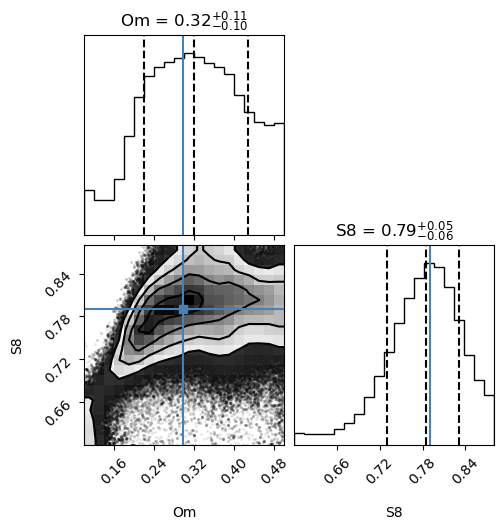

In [13]:
fig = corner.corner(chain, labels=["Om", "S8"], show_titles=True, quantiles=[0.16, 0.5, 0.84], truths=(true_value['Om'], true_value['S8']))
fig.show()